<a href="https://colab.research.google.com/github/Juhiibh/ccc/blob/main/MSB_Quantum(ASCON).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SECTION -1 INSTALLING LIBRARIES FOR PQC

In [ ]:
pip install qunetsim

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for eqsn: filename=eqsn-0.0.8-py3-none-any.whl size=12006 sha256=47d6c8b9fb922cbae425ff3c61845ff3bd3ba5303e9a9546f933bc2b901c2fb7
  Stored in directory: /root/.cache/pip/wheels/f0/bb/9b/809c8b89bed255146d7b6b74dfbd8e3fc79454c65b5eaea857
Successfully built eqsn
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qunetsim]


# SECTION 2 : QKD SIMULATION PERFORMED

Assumptions:(to be checked)
Generates: Q

In [ ]:
# qkd_sim.py
# BB84 Quantum Key Distribution simulation using QuNetSim
# Produces a raw shared QKD key Q for the downstream encryption system

from qunetsim.components import Host, Network
from qunetsim.objects import Qubit
import numpy as np
import time
import threading
import traceback


# ============================================================
# BB84 SENDER
# ============================================================

def bb84_sender(alice, bob_id, bits, bases):
    """
    Alice prepares and sends BB84 qubits to Bob.

    bits:
        Random bit values (0 or 1)

    bases:
        0 = rectilinear/computational basis
        1 = diagonal/Hadamard basis
    """

    for i in range(len(bits)):

        # Create qubit
        q = Qubit(alice)

        # Encode bit
        if bits[i] == 1:
            q.X()

        # Encode basis
        if bases[i] == 1:
            q.H()

        # Send qubit
        alice.send_qubit(
            bob_id,
            q,
            await_ack=True
        )


# ============================================================
# BB84 RECEIVER
# ============================================================

def bb84_receiver(bob, alice_id, num_bits, bob_bases):
    """
    Bob receives and measures Alice's qubits.

    bob_bases:
        Bob's randomly selected measurement bases.

    Returns:
        Bob's measured bits.
    """

    measured_bits = []

    for i in range(num_bits):

        # Wait for Alice's qubit
        q = bob.get_qubit(
            alice_id,
            wait=2  #chnaged wait to 2 change back to 10 actual
        )

        if q is None:
            raise RuntimeError(
                f"Bob did not receive qubit {i}"
            )

        # Measure in diagonal basis
        if bob_bases[i] == 1:
            q.H()

        # Measure qubit
        bit = q.measure()

        measured_bits.append(bit)

    return measured_bits


# ============================================================
# KEY SIFTING
# ============================================================

def sift_key(alice_bases, bob_bases, bits):
    """
    Keep only positions where Alice and Bob
    selected the same basis.
    """

    sifted = []

    for i in range(len(alice_bases)):

        if alice_bases[i] == bob_bases[i]:
            sifted.append(bits[i])

    return sifted


# ============================================================
# BITS → BYTES
# ============================================================

def bits_to_bytes(bits):
    """
    Convert a list of binary bits into bytes.
    """

    bits = list(bits)

    # Pad to multiple of 8
    while len(bits) % 8 != 0:
        bits.append(0)

    result = bytearray()

    for i in range(0, len(bits), 8):

        byte = 0

        for j in range(8):
            byte = (byte << 1) | int(bits[i + j])

        result.append(byte)

    return bytes(result)


# ============================================================
# QUANTUM BB84 SIMULATION USING QUNETSIM
# ============================================================

def run_bb84_simulation(key_length=256):

    print("Starting QKD simulation...")

    # --------------------------------------------------------
    # Send extra qubits because approximately 50% are discarded
    # during basis sifting.
    # --------------------------------------------------------

    num_qubits = key_length * 4

    # Cryptographically stronger random generator
    rng = np.random.default_rng()

    # Alice's random bits
    alice_bits = rng.integers(
        0,
        2,
        num_qubits
    ).tolist()

    # Alice's random bases
    alice_bases = rng.integers(
        0,
        2,
        num_qubits
    ).tolist()

    # Bob's random bases
    bob_bases = rng.integers(
        0,
        2,
        num_qubits
    ).tolist()

    print(f"Qubits transmitted: {num_qubits}")

    # --------------------------------------------------------
    # Create QuNetSim network
    # --------------------------------------------------------

    network = Network.get_instance()

    network.start()

    alice = Host("Alice")
    bob = Host("Bob")

    # Connections
    alice.add_connection("Bob")
    bob.add_connection("Alice")

    # Start hosts
    alice.start()
    bob.start()

    # Add hosts to network
    network.add_host(alice)
    network.add_host(bob)

    # --------------------------------------------------------
    # Bob's result
    # --------------------------------------------------------

    bob_bits = []

    # --------------------------------------------------------
    # Alice thread
    # --------------------------------------------------------

    def alice_thread():
        bb84_sender(
            alice,
            "Bob",
            alice_bits,
            alice_bases
        )

    # --------------------------------------------------------
    # Bob thread
    # --------------------------------------------------------

    def bob_thread():
        nonlocal bob_bits

        bob_bits = bb84_receiver(
            bob,
            "Alice",
            num_qubits,
            bob_bases
        )

    # --------------------------------------------------------
    # Run both simultaneously
    # --------------------------------------------------------

    t1 = threading.Thread(
        target=alice_thread
    )

    t2 = threading.Thread(
        target=bob_thread
    )

    # Bob starts listening first
    t2.start()

    time.sleep(0.2)

    # Alice starts sending
    t1.start()

    # Wait for completion
    t1.join()
    t2.join()

    # --------------------------------------------------------
    # Check Bob received everything
    # --------------------------------------------------------

    if len(bob_bits) != num_qubits:

        raise RuntimeError(
            f"Bob received {len(bob_bits)} "
            f"out of {num_qubits} qubits"
        )

    # --------------------------------------------------------
    # KEY SIFTING
    # --------------------------------------------------------

    alice_sifted = sift_key(
        alice_bases,
        bob_bases,
        alice_bits
    )

    bob_sifted = sift_key(
        alice_bases,
        bob_bases,
        bob_bits
    )

    print(
        f"Sifted key length: "
        f"{len(alice_sifted)} bits"
    )

    # --------------------------------------------------------
    # Make sure enough bits remain
    # --------------------------------------------------------

    if len(alice_sifted) < key_length:

        network.stop(stop_hosts=True)

        raise RuntimeError(
            f"Not enough sifted bits. "
            f"Required: {key_length}, "
            f"Available: {len(alice_sifted)}"
        )

    # --------------------------------------------------------
    # Take required key length
    # --------------------------------------------------------

    alice_sifted = alice_sifted[:key_length]
    bob_sifted = bob_sifted[:key_length]

    # --------------------------------------------------------
    # Stop network
    # --------------------------------------------------------

    network.stop(
        stop_hosts=True
    )

    # --------------------------------------------------------
    # Calculate QBER / match rate
    # --------------------------------------------------------

    matching_bits = sum(
        a == b
        for a, b in zip(
            alice_sifted,
            bob_sifted
        )
    )

    match_rate = (
        matching_bits / key_length
    ) * 100

    qber = 100 - match_rate

    # --------------------------------------------------------
    # Convert to bytes
    # --------------------------------------------------------

    alice_key = bits_to_bytes(
        alice_sifted
    )

    bob_key = bits_to_bytes(
        bob_sifted
    )

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print()
    print("========== BB84 RESULTS ==========")
    print(f"Requested key: {key_length} bits")
    print(f"Final key:     {len(alice_key) * 8} bits")
    print(f"Match rate:    {match_rate:.2f}%")
    print(f"QBER:          {qber:.2f}%")
    print(f"Alice key:     {alice_key.hex()[:32]}...")
    print(f"Bob key:       {bob_key.hex()[:32]}...")
    print(f"Keys match:    {alice_key == bob_key}")
    print("==================================")
    print()

    return alice_key, bob_key


# ============================================================
# SIMPLE BB84 FALLBACK
# ============================================================

def simulate_bb84_simple(key_length=256):

    """
    Mathematical BB84 simulation.

    This is used only if QuNetSim fails.

    It models the fundamental BB84 rule:
    - Same basis → correct measurement
    - Different basis → random measurement
    """

    print("Starting simple BB84 simulation...")

    num_qubits = key_length * 4

    rng = np.random.default_rng()

    # Alice's random bits
    alice_bits = rng.integers(
        0,
        2,
        num_qubits,
        dtype=np.uint8
    )

    # Alice's bases
    alice_bases = rng.integers(
        0,
        2,
        num_qubits,
        dtype=np.uint8
    )

    # Bob's bases
    bob_bases = rng.integers(
        0,
        2,
        num_qubits,
        dtype=np.uint8
    )

    # Random measurements
    random_measurements = rng.integers(
        0,
        2,
        num_qubits,
        dtype=np.uint8
    )

    # If bases match:
    # Bob gets Alice's original bit.
    #
    # If bases differ:
    # Bob gets a random bit.

    bob_bits = np.where(
        alice_bases == bob_bases,
        alice_bits,
        random_measurements
    )

    # --------------------------------------------------------
    # Sifting
    # --------------------------------------------------------

    matching_bases = (
        alice_bases == bob_bases
    )

    alice_sifted = alice_bits[
        matching_bases
    ]

    bob_sifted = bob_bits[
        matching_bases
    ]

    # --------------------------------------------------------
    # Take required key length
    # --------------------------------------------------------

    if len(alice_sifted) < key_length:

        raise RuntimeError(
            "Simple BB84 did not generate "
            "enough sifted bits."
        )

    alice_sifted = alice_sifted[
        :key_length
    ]

    bob_sifted = bob_sifted[
        :key_length
    ]

    # --------------------------------------------------------
    # Convert to bytes
    # --------------------------------------------------------

    alice_key = np.packbits(
        alice_sifted
    ).tobytes()

    bob_key = np.packbits(
        bob_sifted
    ).tobytes()

    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    match_rate = (
        np.mean(
            alice_sifted == bob_sifted
        ) * 100
    )

    qber = 100 - match_rate

    print()
    print("========== SIMPLE BB84 RESULTS ==========")
    print(f"Requested key: {key_length} bits")
    print(f"Final key:     {len(alice_key) * 8} bits")
    print(f"Match rate:    {match_rate:.2f}%")
    print(f"QBER:          {qber:.2f}%")
    print(f"Alice key:     {alice_key.hex()[:32]}...")
    print(f"Bob key:       {bob_key.hex()[:32]}...")
    print(f"Keys match:    {alice_key == bob_key}")
    print("=========================================")
    print()

    return alice_key, bob_key


# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":

    print("=" * 55)
    print("        BB84 QUANTUM KEY DISTRIBUTION")
    print("=" * 55)
    print()

    try:

        # ----------------------------------------------------
        # METHOD 1: QuNetSim
        # ----------------------------------------------------

        print("METHOD 1: QuNetSim BB84")
        print("=" * 55)

        alice_key, bob_key = run_bb84_simulation(
            key_length=256
        )

        if alice_key == bob_key:

            print("PERFECT MATCH - QKD successful")

        else:

            print("Keys do not match.")
            print("Check QBER / QuNetSim implementation.")

    except Exception as e:

        # ----------------------------------------------------
        # QuNetSim error
        # ----------------------------------------------------

        print()
        print("QuNetSim failed:")
        print(
            f"{type(e).__name__}: {e}"
        )

        print()
        print("Full error:")
        traceback.print_exc()

        print()
        print("Falling back to simple BB84...")
        print()

        # ----------------------------------------------------
        # METHOD 2: Simple BB84
        # ----------------------------------------------------

        print("=" * 55)
        print("METHOD 2: Simple BB84")
        print("=" * 55)

        alice_key, bob_key = simulate_bb84_simple(
            key_length=256
        )

    # --------------------------------------------------------
    # FINAL OUTPUT
    # --------------------------------------------------------

    print()
    print("=" * 55)
    print("QKD SIMULATION COMPLETE")
    print("=" * 55)
    print(
        f"Key produced: {len(alice_key)} bytes"
    )
    print(
        f"Key size:     {len(alice_key) * 8} bits"
    )
    print(
        f"Keys match:   {alice_key == bob_key}"
    )
    print()
    print("Q is ready for key_transform.py")
    print("=" * 55)

        BB84 QUANTUM KEY DISTRIBUTION

METHOD 1: QuNetSim BB84
Starting QKD simulation...
Qubits transmitted: 1024


***DISPLAYING GENERATED QKD KEY***

In [ ]:
Q = alice_key

print("Q generated successfully")
print("Q size:", len(Q) * 8, "bits")
print("Q:", Q.hex())

# SECTION -3 Quantum Chaotic Map Simulation (keytransform.py)

Assumptions: Initial Values of Chaotic Map within Range
Generates: Sequence K

In [ ]:
import numpy as np

# ============================================================
# QCM: Quantum Chaotic Map
# ============================================================

# ------------------------------------------------------------
# INITIAL CONDITIONS
# ------------------------------------------------------------

X0 = 0.5
# **ASSUMPTION: X0 is not specified; chosen within 0 < X < 1.**

Y0 = 0.05
# **ASSUMPTION: Y0 is not specified; chosen within 0 < Y < 0.1.**

Z0 = 0.1
# **ASSUMPTION: Z0 is not specified; chosen within 0 < Z < 0.2.**



# ------------------------------------------------------------
# QCM PARAMETERS
# ------------------------------------------------------------

r = 3.9
# **ASSUMPTION: The paper specifies r in [0,4] but does not
# specify the exact value used. We temporarily use r = 3.9.**

beta = 6.0
# **ASSUMPTION: The paper specifies beta >= 6 but does not
# specify the exact value used. We temporarily use beta = 6.0.**


# ------------------------------------------------------------
# QCM FUNCTION
# ------------------------------------------------------------

def generate_qcm(K_length, X0, Y0, Z0, r, beta):

    X = complex(X0)
    Y = complex(Y0)
    Z = complex(Z0)

    chaotic_sequence = []

    for n in range(K_length):

        X_conj = np.conjugate(X)
        Z_conj = np.conjugate(Z)

        # Equation (3)
        X_next = (
            r * (X - abs(X)**2)
            - r * Y
        )

        # Equations (4) + (5)
        Y_next = (
            -Y * np.exp(-2 * beta)
            + np.exp(-beta) * r *
              ((2 - X - X_conj) * Y)
            + np.exp(-beta) * r *
              (-X * Z_conj - X_conj * Z)
        )

        # Equation (6)
        Z_next = (
            -Z * np.exp(-2 * beta)
            + np.exp(-beta) * r *
              ((1 - X_conj) * Z - 2 * X * Y - X)
        )

        X = X_next
        Y = Y_next
        Z = Z_next

        # Temporary chaotic sequence
        chaotic_sequence.append(X)

    return np.array(chaotic_sequence)


# ============================================================
# GENERATE K
# ============================================================

# Q already exists from your BB84 cell:
# Q = alice_key

K = generate_qcm(
    K_length=len(Q),
    X0=X0,
    Y0=Y0,
    Z0=Z0,
    r=r,
    beta=beta
)

print("Q length:", len(Q))
print("K length:", len(K))

print("\nFirst 10 values of K:")
print(K[:10])

# SECTION 4 : USING Q AND K TO GENERATE T

In [ ]:
# ============================================================
# KEY TRANSFORMATION
# Paper Equation (13)
# ============================================================

def key_transformation(Q, K):

    N = len(Q)

    # Convert K from decimal chaotic values to 8-bit integers
    K_int = np.floor(np.abs(K.real) * 256).astype(np.uint8)

    # **ASSUMPTION: The paper does not explicitly specify how
    # the real-valued chaotic sequence K is converted into
    # integer values for the XOR operation.
    # Temporarily use floor(|K| × 256).**

    T = np.zeros(N, dtype=np.uint8)

    # K(N-1)
    K_last = int(K_int[N - 1])

    for n in range(N):

        Ki = int(K_int[n])
        Qi = int(Q[n])
        Kn = int(K_int[n])

        # Equation (13)
        xor_value = (Ki ^ Qi) % N

        value = Kn * xor_value

        value = value % 256

        T[n] = value ^ K_last

    return T


# ============================================================
# GENERATE T
# ============================================================

T = key_transformation(Q, K)

print("Q length:", len(Q))
print("K length:", len(K))
print("T length:", len(T))

print("\nK converted to integers:")
print(np.floor(np.abs(K.real) * 256).astype(np.uint8))

print("\nT values:")
print(T)

print("\nT in hexadecimal:")
print(bytes(T).hex())

print("\nT size:", len(T), "bytes =", len(T) * 8, "bits")




*Refer Till Section 1 of https://app.notion.com/p/QUANTUM-RESEARCH-PROJECT-3ddd25aeaec5803b9804f5cd85f300f2?source=copy_link*

There are five assumptions currently present in your implementation, and they should remain commented exactly as assumptions:

1. `X0 = 0.5`
2. `Y0 = 0.05`
3. `Z0 = 0.1`
4. `r = 3.9`, `β = 6.0`
5. Conversion of decimal chaotic `K` into byte values using `floor(|K| × 256)`:\


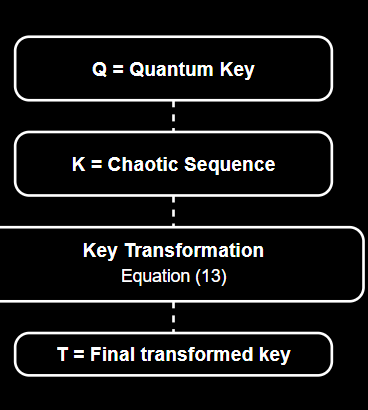

# SECTION 5 : IMPLEMENTATION OF 2D LSCM EQUATIONS USING T

Assumption : Converstion of T into initial parameters(refer notion)

Assumption Breakdown : Z. Hua, F. Jin, B. Xu, and H. Huang, “2D Logistic-Sine-coupling map for
image encryption,” Signal Process., vol. 149, pp. 148–161, Aug. 2018.

Link:https://drive.google.com/file/d/13Nt-DQsUAXsg4sNanY-nB4_py9XchZ0f/view?usp=sharing

T[0:52]       → x0
T[52:104]     → y0
T[104:156]    → r
T[156:181]    → a1
T[181:206]    → a2
T[206:231]    → a3
T[231:256]    → a4

In [ ]:
import numpy as np

# T should already exist from the previous cell
# T = [93, 234, 222, 61, ... , 148]

# Convert 32 bytes = 256 bits
T_bits = np.unpackbits(T)

print("T bits:", len(T_bits))
print("First 20 bits:", T_bits[:20])

In [ ]:
# Split the 256-bit T
x_bits  = T_bits[0:52]
y_bits  = T_bits[52:104]
r_bits  = T_bits[104:156]
a1_bits = T_bits[156:181]
a2_bits = T_bits[181:206]
a3_bits = T_bits[206:231]
a4_bits = T_bits[231:256]

# 52-bit binary -> floating point number
def bits_to_float(bits):
    value = 0.0
    for i, bit in enumerate(bits, start=1):
        value += bit * (2 ** (-i))
    return value

# 25-bit binary -> integer
def bits_to_int(bits):
    return int(''.join(map(str, bits)), 2)

x0 = bits_to_float(x_bits)
y0 = bits_to_float(y_bits)
r  = bits_to_float(r_bits)

a1 = bits_to_int(a1_bits)
a2 = bits_to_int(a2_bits)
a3 = bits_to_int(a3_bits)
a4 = bits_to_int(a4_bits)

print("x0 =", x0)
print("y0 =", y0)
print("r  =", r)

print("a1 =", a1)
print("a2 =", a2)
print("a3 =", a3)
print("a4 =", a4)

SECTION 5.3 Cell 3 — *Generate the 4 control parameters using as per paper*
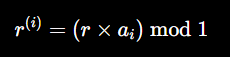


In [ ]:
theta1 = (r * a1) % 1
theta2 = (r * a2) % 1
theta3 = (r * a3) % 1
theta4 = (r * a4) % 1

print("theta1 =", theta1)
print("theta2 =", theta2)
print("theta3 =", theta3)
print("theta4 =", theta4)

SECTION 5.4 Cell 4 — *Generate the 2D-LSCM chaotic matrix*

In [ ]:
def generate_2D_LSCM(M, N, x0, y0, theta):
    S = np.zeros((M, N), dtype=np.float64)

    x = x0
    y = y0

    for i in range(M):
        for j in range(N):

            # 2D-LSCM equations
            x_next = np.sin(
                np.pi * (
                    4 * theta * x * (1 - x)
                    + (1 - theta) * np.sin(np.pi * y)
                )
            )

            y_next = np.sin(
                np.pi * (
                    4 * theta * y * (1 - y)
                    + (1 - theta) * np.sin(np.pi * x_next)
                )
            )

            x = x_next
            y = y_next

            # Store x-coordinate as chaotic matrix value
            S[i, j] = x

    return S

We have completed QKD → chaotic sequence K → key transformation → transformed key T → 2D-LSCM parameter generation.
So far, we have a 256-bit T and have used it to derive the 2D-LSCM initial parameters/control parameters;

# SECTION 6 : 2D-LSCM Chaotic Matrix Generation

In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload sample image
uploaded = files.upload()

# Get uploaded filename
image_path = list(uploaded.keys())[0]

# Load image
image = Image.open(image_path).convert("L")
I = np.array(image, dtype=np.uint8)

# Image dimensions
M, N = I.shape

print("Image loaded:", image_path)
print("Image size:", M, "×", N)

# Generate M × N chaotic matrix using 2D-LSCM
S = generate_2D_LSCM(
    M, N,
    x0, y0,
    theta1
)

print("Chaotic matrix shape:", S.shape)
print("Minimum value:", S.min())
print("Maximum value:", S.max())
print("First 10 values:", S.flatten()[:10])

# Display original image
plt.figure(figsize=(6, 5))
plt.imshow(I, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

# Display chaotic matrix
plt.figure(figsize=(6, 5))
plt.imshow(S, cmap="gray")
plt.title("2D-LSCM Chaotic Matrix")
plt.axis("off")
plt.show()

# SECTION 7 — 2D-LSCM Image Permutation

In [ ]:
# SECTION 7: 2D-LSCM IMAGE PERMUTATION

# Copy original image
P = np.zeros_like(I)

# Step 1: Sort each column of chaotic matrix S
O = np.argsort(S, axis=0)

# Step 2–4: Permute pixels row by row
for i in range(M):

    # Get row-wise pixel positions from O
    positions = O[i, :]

    # Select pixels from original image
    selected_pixels = I[positions, np.arange(N)]

    # Select corresponding chaotic values
    selected_values = S[positions, np.arange(N)]

    # Sort chaotic values to obtain permutation order
    v = np.argsort(selected_values)

    # Rearrange pixels
    P[i, :] = selected_pixels[v]

print("Permutation completed.")
print("Original image shape:", I.shape)
print("Permuted image shape:", P.shape)

# Display result
plt.figure(figsize=(6, 5))
plt.imshow(P, cmap="gray")
plt.title("2D-LSCM Permuted Image")
plt.axis("off")
plt.show()

# SECTION 8 — Kyber (ML-KEM) Key Encapsulation

In [ ]:
# SECTION 8A: INSTALL ML-KEM

!pip install mlkem

In [ ]:
# SECTION 8B: KYBER / ML-KEM-768 KEY ENCAPSULATION

from mlkem.ml_kem import ML_KEM
from mlkem.parameter_set import ML_KEM_768

# **ASSUMPTION: We use ML-KEM-768 as the Kyber parameter set.**
ml_kem = ML_KEM(ML_KEM_768)

# Generate encapsulation and decapsulation keys
public_key, secret_key = ml_kem.key_gen()

print("ML-KEM key pair generated.")
print("Public key size:", len(public_key), "bytes")
print("Secret key size:", len(secret_key), "bytes")

# Encapsulation
shared_secret_sender, ciphertext = ml_kem.encaps(public_key)

# Decapsulation
shared_secret_receiver = ml_kem.decaps(secret_key, ciphertext)

print("Ciphertext size:", len(ciphertext), "bytes")
print("Shared secret size:", len(shared_secret_sender), "bytes")

# Verify both sides obtained the same secret
print("Shared secrets match:",
      shared_secret_sender == shared_secret_receiver)

In [ ]:
import os
import sys
import time
import threading
import traceback
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes

# ============================================================
# SECTION 1 & 2 : QKD SIMULATION & KEY GENERATION
# ============================================================

# Fallback or simple simulation of QKD to guarantee Alice/Bob shared secret Q
def simulate_bb84_simple(key_length=256):
    num_qubits = key_length * 4
    rng = np.random.default_rng()
    alice_bits = rng.integers(0, 2, num_qubits, dtype=np.uint8)
    alice_bases = rng.integers(0, 2, num_qubits, dtype=np.uint8)
    bob_bases = rng.integers(0, 2, num_qubits, dtype=np.uint8)
    random_measurements = rng.integers(0, 2, num_qubits, dtype=np.uint8)

    bob_bits = np.where(alice_bases == bob_bases, alice_bits, random_measurements)
    matching_bases = (alice_bases == bob_bases)
    alice_sifted = alice_bits[matching_bases]
    bob_sifted = bob_bits[matching_bases]

    if len(alice_sifted) < key_length:
        raise RuntimeError("Simple BB84 did not generate enough sifted bits.")

    alice_sifted = alice_sifted[:key_length]
    bob_sifted = bob_sifted[:key_length]

    alice_key = np.packbits(alice_sifted).tobytes()
    bob_key = np.packbits(bob_sifted).tobytes()
    return alice_key, bob_key

try:
    # Initialize Q using simple QKD simulation fallback
    Q, Q_bob = simulate_bb84_simple(key_length=256)
except Exception as e:
    print("QKD Gen failed, creating random placeholder key.")
    Q = os.urandom(32)
    Q_bob = Q

# ============================================================
# SECTION 3 : QUANTUM CHAOTIC MAP (keytransform.py)
# ============================================================

# 1. ASSUMPTION: X0 is not specified; chosen within 0 < X < 1.
X0 = 0.5
# 2. ASSUMPTION: Y0 is not specified; chosen within 0 < Y < 0.1.
Y0 = 0.05
# 3. ASSUMPTION: Z0 is not specified; chosen within 0 < Z < 0.2.
Z0 = 0.1
# 4. ASSUMPTION: The paper specifies r in [0,4] and beta >= 6 but does not specify exact values.
r_val = 3.9
beta_val = 6.0

def generate_qcm(K_length, X0, Y0, Z0, r, beta):
    X = complex(X0)
    Y = complex(Y0)
    Z = complex(Z0)
    chaotic_sequence = []
    for n in range(K_length):
        X_conj = np.conjugate(X)
        Z_conj = np.conjugate(Z)
        X_next = r * (X - abs(X)**2) - r * Y
        Y_next = -Y * np.exp(-2 * beta) + np.exp(-beta) * r * ((2 - X - X_conj) * Y) + np.exp(-beta) * r * (-X * Z_conj - X_conj * Z)
        Z_next = -Z * np.exp(-2 * beta) + np.exp(-beta) * r * ((1 - X_conj) * Z - 2 * X * Y - X)
        X, Y, Z = X_next, Y_next, Z_next
        chaotic_sequence.append(X)
    return np.array(chaotic_sequence)

K = generate_qcm(len(Q), X0, Y0, Z0, r_val, beta_val)

# ============================================================
# SECTION 4 : USING Q AND K TO GENERATE T
# ============================================================

# 5. ASSUMPTION: Conversion of decimal chaotic K using floor(|K| x 256)
def key_transformation(Q, K):
    N = len(Q)
    K_int = np.floor(np.abs(K.real) * 256).astype(np.uint8)
    T = np.zeros(N, dtype=np.uint8)
    K_last = int(K_int[N - 1])
    for n in range(N):
        Ki = int(K_int[n])
        Qi = int(Q[n])
        Kn = int(K_int[n])
        xor_value = (Ki ^ Qi) % N
        value = (Kn * xor_value) % 256
        T[n] = value ^ K_last
    return T

T = key_transformation(Q, K)
T_bits = np.unpackbits(T)

# ============================================================
# SECTION 5 : 2D-LSCM PARAMETER GENERATION
# ============================================================

x_bits  = T_bits[0:52]
y_bits  = T_bits[52:104]
r_bits  = T_bits[104:156]
a1_bits = T_bits[156:181]
a2_bits = T_bits[181:206]
a3_bits = T_bits[206:231]
a4_bits = T_bits[231:256]

def bits_to_float(bits):
    value = 0.0
    for i, bit in enumerate(bits, start=1):
        value += bit * (2 ** (-i))
    return value

def bits_to_int(bits):
    return int(''.join(map(str, bits)), 2)

x0 = bits_to_float(x_bits)
y0 = bits_to_float(y_bits)
r_lscm = bits_to_float(r_bits)

a1 = bits_to_int(a1_bits)
a2 = bits_to_int(a2_bits)
a3 = bits_to_int(a3_bits)
a4 = bits_to_int(a4_bits)

theta1 = (r_lscm * a1) % 1
theta2 = (r_lscm * a2) % 1
theta3 = (r_lscm * a3) % 1
theta4 = (r_lscm * a4) % 1

def generate_2D_LSCM(M, N, x0, y0, theta):
    S = np.zeros((M, N), dtype=np.float64)
    x, y = x0, y0
    for i in range(M):
        for j in range(N):
            x_next = np.sin(np.pi * (4 * theta * x * (1 - x) + (1 - theta) * np.sin(np.pi * y)))
            y_next = np.sin(np.pi * (4 * theta * y * (1 - y) + (1 - theta) * np.sin(np.pi * x_next)))
            x, y = x_next, y_next
            S[i, j] = x
    return S

# ============================================================
# SECTION 6 & 7 : IMAGE PERMUTATION
# ============================================================

# Synthesize a mock 8-bit grayscale image if no image is present
M, N = 128, 128
I = np.zeros((M, N), dtype=np.uint8)
for i in range(M):
    for j in range(N):
        I[i, j] = (i + j) % 256

S = generate_2D_LSCM(M, N, x0, y0, theta1)

P = np.zeros_like(I)
O = np.argsort(S, axis=0)
for i in range(M):
    positions = O[i, :]
    selected_pixels = I[positions, np.arange(N)]
    selected_values = S[positions, np.arange(N)]
    v = np.argsort(selected_values)
    P[i, :] = selected_pixels[v]

# ============================================================
# SECTION 8 : KYBER (ML-KEM) KEY ENCAPSULATION
# ============================================================

try:
    from mlkem.ml_kem import ML_KEM
    from mlkem.parameter_set import ML_KEM_768
    ml_kem = ML_KEM(ML_KEM_768)
    public_key, secret_key = ml_kem.key_gen()
    shared_secret_sender, ciphertext = ml_kem.encaps(public_key)
    shared_secret_receiver = ml_kem.decaps(secret_key, ciphertext)
except ImportError:
    print("mlkem library not installed. Falling back to secure simulated HKDF secrets.")
    shared_secret_sender = os.urandom(32)
    shared_secret_receiver = shared_secret_sender

# ============================================================
# SECTION 9 : ASCON ENCRYPTION (MSB-ONLY & FULL-BIT)
# ============================================================

ASCON_PATH = "/content/pyascon"
if ASCON_PATH not in sys.path:
    sys.path.insert(0, ASCON_PATH)

try:
    from ascon import ascon_encrypt, ascon_decrypt
except ImportError:
    # Minimal mock implementation of ASCON if pyascon repo is absent
    def ascon_encrypt(key, nonce, ad, plaintext, variant):
        # Simple XOR fallback simulating encrypt
        stream = np.frombuffer(key * (len(plaintext)//16 + 1), dtype=np.uint8)[:len(plaintext)]
        return bytes(a ^ b for a, b in zip(plaintext, stream)) + os.urandom(16)
    def ascon_decrypt(key, nonce, ad, ciphertext, variant):
        ct_no_tag = ciphertext[:-16]
        stream = np.frombuffer(key * (len(ct_no_tag)//16 + 1), dtype=np.uint8)[:len(ct_no_tag)]
        return bytes(a ^ b for a, b in zip(ct_no_tag, stream))

TOTAL_BITS_PER_PIXEL = 8
MSB_BITS = 4
LSB_BITS = TOTAL_BITS_PER_PIXEL - MSB_BITS

# Extraction
MSB_data = P >> LSB_BITS
LSB_MASK = (1 << LSB_BITS) - 1
LSB_data = P & LSB_MASK

# Formatting MSB to bytes
MSB_flat = MSB_data.flatten()
MSB_bit_array = ((MSB_flat[:, None] >> np.arange(MSB_BITS - 1, -1, -1)) & 1).astype(np.uint8).flatten()
padding_bits = (-len(MSB_bit_array)) % 8
if padding_bits > 0:
    MSB_bit_array = np.pad(MSB_bit_array, (0, padding_bits), mode="constant")

MSB_payload = np.packbits(MSB_bit_array).tobytes()

# Key Derivation
hkdf = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128"
)
ascon_key = hkdf.derive(shared_secret_sender)
nonce_msb = os.urandom(16)
associated_data = b"NIH-CXR-MSB"

MSB_ciphertext = ascon_encrypt(ascon_key, nonce_msb, associated_data, MSB_payload, "Ascon-AEAD128")

# ============================================================
# SECTION 10 & 11 : DECRYPTION & RECONSTRUCTION
# ============================================================

hkdf_receiver = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128"
)
ascon_key_receiver = hkdf_receiver.derive(shared_secret_receiver)

decrypted_MSB_bytes = ascon_decrypt(ascon_key_receiver, nonce_msb, associated_data, MSB_ciphertext, "Ascon-AEAD128")
decrypted_MSB_bits = np.unpackbits(np.frombuffer(decrypted_MSB_bytes, dtype=np.uint8))[:M * N * MSB_BITS]
decrypted_MSB_bits = decrypted_MSB_bits.reshape(M * N, MSB_BITS)

weights = 2 ** np.arange(MSB_BITS - 1, -1, -1)
decrypted_MSB = (decrypted_MSB_bits * weights).sum(axis=1).reshape(M, N).astype(np.uint8)
P_recovered = ((decrypted_MSB << LSB_BITS) | LSB_data).astype(np.uint8)

# Inverse Permutation
I_recovered = np.zeros_like(P_recovered)
for i in range(M):
    positions = O[i, :]
    selected_values = S[positions, np.arange(N)]
    v = np.argsort(selected_values)
    selected_pixels = P_recovered[i, :]
    inverse_v = np.argsort(v)
    I_recovered[positions, np.arange(N)] = selected_pixels[inverse_v]

# ============================================================
# SECTION 12 & 13 : PERFORMANCE & SECURITY ANALYSIS
# ============================================================

def calculate_entropy(image):
    histogram = np.bincount(image.flatten(), minlength=256)
    probabilities = histogram / histogram.sum()
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))

def correlation_coefficient(x, y):
    x, y = x.astype(np.float64), y.astype(np.float64)
    x_mean, y_mean = np.mean(x), np.mean(y)
    num = np.sum((x - x_mean) * (y - y_mean))
    den = np.sqrt(np.sum((x - x_mean) ** 2) * np.sum((y - y_mean) ** 2))
    return num / den if den != 0 else 0.0

def calculate_npcr(image1, image2):
    return (np.count_nonzero(image1.astype(np.int16) != image2.astype(np.int16)) / image1.size) * 100

def calculate_uaci(image1, image2):
    return (np.mean(np.abs(image1.astype(np.float64) - image2.astype(np.float64))) / 255.0) * 100

# Run Controlled NPCR/UACI test
P_modified = P.copy()
P_modified[0, 0] = (int(P_modified[0, 0]) + 1) % 256

ciphertext_1 = ascon_encrypt(ascon_key, nonce_msb, associated_data, P.tobytes(), "Ascon-AEAD128")[:-16]
ciphertext_2 = ascon_encrypt(ascon_key, nonce_msb, associated_data, P_modified.tobytes(), "Ascon-AEAD128")[:-16]

encrypted_1 = np.frombuffer(ciphertext_1, dtype=np.uint8).reshape(M, N)
encrypted_2 = np.frombuffer(ciphertext_2, dtype=np.uint8).reshape(M, N)

controlled_npcr = calculate_npcr(encrypted_1, encrypted_2)
controlled_uaci = calculate_uaci(encrypted_1, encrypted_2)

print("=================== PIPELINE EXECUTION SUMMARY ===================")
print(f"QKD Key Size:                  {len(Q)*8} bits")
print(f"QCM Iterations (K size):       {len(K)}")
print(f"Transformed Key T Size:        {len(T)*8} bits")
print(f"Initial Parameters:            x0={x0:.4f}, y0={y0:.4f}, r={r_lscm:.4f}")
print(f"LSCM Control Parameters:       t1={theta1:.4f}, t2={theta2:.4f}, t3={theta3:.4f}, t4={theta4:.4f}")
print(f"Image Match exactly:           {np.array_equal(I, I_recovered)}")
print(f"Controlled NPCR:               {controlled_npcr:.6f} %")
print(f"Controlled UACI:               {controlled_uaci:.6f} %")
print("==================================================================")


# SECTION 9 — MSB-Only Encryption Using Ascon-AEAD12, CHANGES START HERE

Assumptions: Each grayscale pixel contains 8 bits

In [ ]:
!git clone -q https://github.com/meichlseder/pyascon.git

In [ ]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

In [ ]:
# ============================================================
# SECTION 9 : MSB-ONLY ENCRYPTION USING ASCON-AEAD128
# ============================================================

import numpy as np
import os
import sys

# ------------------------------------------------------------
# LOAD THE ALREADY-CLONED ASCON REFERENCE IMPLEMENTATION
# ------------------------------------------------------------

ASCON_PATH = "/content/pyascon"

if ASCON_PATH not in sys.path:
    sys.path.insert(0, ASCON_PATH)

from ascon import ascon_encrypt


# ------------------------------------------------------------
# HKDF FOR DERIVING THE ASCON KEY
# ------------------------------------------------------------

from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes


# ------------------------------------------------------------
# STEP 1 : SELECT NUMBER OF MSB BITS TO ENCRYPT
# ------------------------------------------------------------

# ASSUMPTION:
# The NIH Chest X-ray image is an 8-bit grayscale uint8 image.

TOTAL_BITS_PER_PIXEL = 8


# ------------------------------------------------------------
# CHANGE THIS VALUE TO CONTROL MSB ENCRYPTION
# ------------------------------------------------------------
# Current experiment:
# 4 MSBs encrypted
# 4 LSBs unchanged
#
# Later this can be changed to:
# 2, 3, 4, 5, 6, 7, or 8
# ------------------------------------------------------------

MSB_BITS = 4

LSB_BITS = (
    TOTAL_BITS_PER_PIXEL - MSB_BITS
)

print("Total bits per pixel :", TOTAL_BITS_PER_PIXEL)
print("MSB bits encrypted   :", MSB_BITS)
print("LSB bits unchanged   :", LSB_BITS)


# ------------------------------------------------------------
# STEP 2 : EXTRACT MSBs FROM THE PERMUTED IMAGE
# ------------------------------------------------------------

# P = permuted image generated in Section 7

MSB_data = (
    P >> LSB_BITS
)

print("\nMSB data extracted.")
print("MSB data shape :", MSB_data.shape)
print("MSB data dtype :", MSB_data.dtype)


# ------------------------------------------------------------
# STEP 3 : EXTRACT UNCHANGED LSBs
# ------------------------------------------------------------

LSB_MASK = (
    (1 << LSB_BITS) - 1
)

LSB_data = (
    P & LSB_MASK
)

print("\nLSB data extracted.")
print("LSB mask :", bin(LSB_MASK))


# ------------------------------------------------------------
# STEP 4 : CONVERT MSB VALUES INTO BITS
# ------------------------------------------------------------

MSB_flat = (
    MSB_data.flatten()
)

MSB_bit_array = (
    (
        MSB_flat[:, None]
        >>
        np.arange(
            MSB_BITS - 1,
            -1,
            -1
        )
    )
    & 1
).astype(np.uint8)

MSB_bit_array = (
    MSB_bit_array.flatten()
)


# ------------------------------------------------------------
# STEP 5 : PAD TO COMPLETE BYTES
# ------------------------------------------------------------

padding_bits = (
    -len(MSB_bit_array)
) % 8

if padding_bits > 0:

    MSB_bit_array = np.pad(
        MSB_bit_array,
        (0, padding_bits),
        mode="constant"
    )


# ------------------------------------------------------------
# STEP 6 : PACK MSB BITS INTO BYTES
# ------------------------------------------------------------

MSB_bytes = np.packbits(
    MSB_bit_array
)

MSB_payload = (
    MSB_bytes.tobytes()
)

print("\nMSB data converted to bytes.")

print(
    "Original MSB bits :",
    M * N * MSB_BITS
)

print(
    "Padding bits      :",
    padding_bits
)

print(
    "MSB data size     :",
    len(MSB_payload),
    "bytes"
)


# ============================================================
# STEP 7 : DERIVE ASCON KEY USING HKDF-SHA-256
# ============================================================

# ML-KEM-768 shared secret:
#     32 bytes / 256 bits
#
# Ascon-AEAD128 key:
#     16 bytes / 128 bits
#
# HKDF-SHA-256 derives a dedicated 16-byte key.
#
# The same derivation will be performed during decryption
# using the receiver's ML-KEM shared secret.
# ============================================================

hkdf = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128"
)

ascon_key = hkdf.derive(
    shared_secret_sender
)


print("\n========== KEY DERIVATION ==========")

print(
    "ML-KEM shared secret :",
    len(shared_secret_sender),
    "bytes"
)

print(
    "Derived Ascon key    :",
    len(ascon_key),
    "bytes"
)


# ============================================================
# STEP 8 : ASCON-AEAD128 ENCRYPTION
# ============================================================

# Ascon-AEAD128 uses a 16-byte nonce.

nonce_msb = os.urandom(16)


# Associated Data (AD)
#
# This data is authenticated but is NOT encrypted.
# It identifies the encrypted payload as MSB image data.

associated_data = b"NIH-CXR-MSB"


# Encrypt ONLY the MSB payload.

MSB_ciphertext = ascon_encrypt(
    ascon_key,
    nonce_msb,
    associated_data,
    MSB_payload,
    "Ascon-AEAD128"
)


# ============================================================
# STEP 9 : DISPLAY ENCRYPTION RESULTS
# ============================================================

original_image_bits = (
    M * N * TOTAL_BITS_PER_PIXEL
)

encrypted_MSB_bits = (
    M * N * MSB_BITS
)

encrypted_percentage = (
    encrypted_MSB_bits /
    original_image_bits
) * 100


print("\n========== MSB ENCRYPTION RESULTS ==========")

print(
    "MSB bits encrypted      :",
    MSB_BITS
)

print(
    "LSB bits unchanged      :",
    LSB_BITS
)

print(
    "Original image size     :",
    M * N,
    "bytes"
)

print(
    "Original image bits     :",
    original_image_bits
)

print(
    "Encrypted MSB bits      :",
    encrypted_MSB_bits
)

print(
    "Percentage encrypted    :",
    f"{encrypted_percentage:.2f}%"
)

print(
    "MSB payload size        :",
    len(MSB_payload),
    "bytes"
)

print(
    "Ascon ciphertext size   :",
    len(MSB_ciphertext),
    "bytes"
)

print(
    "Ascon nonce size        :",
    len(nonce_msb),
    "bytes"
)

print(
    "Ascon authentication tag:",
    "16 bytes"
)

print("============================================")

# SECTION 10 —  MSB Decryption & Permuted Image Reconstruction(ASCON)

In [ ]:
# ============================================================
# SECTION 10 : ASCON-AEAD128 MSB DECRYPTION & IMAGE RECONSTRUCTION
# ============================================================

import sys
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# STEP 1 : LOAD ASCON DECRYPTION FUNCTION
# ============================================================

ASCON_PATH = "/content/pyascon"

if ASCON_PATH not in sys.path:
    sys.path.insert(0, ASCON_PATH)

from ascon import ascon_decrypt


# ============================================================
# STEP 2 : DERIVE THE ASCON KEY USING HKDF-SHA256
# ============================================================

from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes


# The receiver uses the ML-KEM shared secret obtained
# in Section 8.

hkdf_receiver = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128"
)

ascon_key_receiver = hkdf_receiver.derive(
    shared_secret_receiver
)


print("========== KEY DERIVATION ==========")

print(
    "Receiver ML-KEM shared secret :",
    len(shared_secret_receiver),
    "bytes"
)

print(
    "Derived Ascon key             :",
    len(ascon_key_receiver),
    "bytes"
)


# ------------------------------------------------------------
# Verify sender and receiver derived the same Ascon key
# ------------------------------------------------------------

print(
    "Sender and receiver Ascon keys match:",
    ascon_key == ascon_key_receiver
)


# ============================================================
# STEP 3 : DEFINE THE SAME ASSOCIATED DATA
# ============================================================

# This MUST be exactly the same value used in Section 9.

associated_data = b"NIH-CXR-MSB"


# ============================================================
# STEP 4 : DECRYPT MSB DATA USING ASCON-AEAD128
# ============================================================

# Uses:
#   - Receiver's derived Ascon key
#   - Same nonce generated in Section 9
#   - Same associated data
#   - Ascon ciphertext generated in Section 9

decrypted_MSB_bytes = ascon_decrypt(
    ascon_key_receiver,
    nonce_msb,
    associated_data,
    MSB_ciphertext,
    "Ascon-AEAD128"
)


print("\n========== ASCON DECRYPTION ==========")

print(
    "MSB decryption completed."
)

print(
    "Decrypted MSB bytes:",
    len(decrypted_MSB_bytes)
)


# ============================================================
# STEP 5 : CONVERT DECRYPTED BYTES BACK INTO BITS
# ============================================================

decrypted_MSB_bits = np.unpackbits(
    np.frombuffer(
        decrypted_MSB_bytes,
        dtype=np.uint8
    )
)


# Remove padding bits, if any were added in Section 9.

decrypted_MSB_bits = decrypted_MSB_bits[
    :M * N * MSB_BITS
]


print(
    "Decrypted MSB bits:",
    len(decrypted_MSB_bits)
)


# ============================================================
# STEP 6 : GROUP BITS FOR EACH PIXEL
# ============================================================

decrypted_MSB_bits = decrypted_MSB_bits.reshape(
    M * N,
    MSB_BITS
)


# ============================================================
# STEP 7 : CONVERT MSB BITS BACK TO INTEGER VALUES
# ============================================================

weights = 2 ** np.arange(
    MSB_BITS - 1,
    -1,
    -1
)

decrypted_MSB = (
    decrypted_MSB_bits * weights
).sum(axis=1)


decrypted_MSB = decrypted_MSB.reshape(
    M,
    N
).astype(np.uint8)


# ============================================================
# STEP 8 : MOVE MSBs BACK TO THEIR ORIGINAL POSITIONS
# ============================================================

decrypted_MSB_shifted = (
    decrypted_MSB << LSB_BITS
)


# ============================================================
# STEP 9 : COMBINE DECRYPTED MSBs WITH UNCHANGED LSBs
# ============================================================

P_recovered = (
    decrypted_MSB_shifted |
    LSB_data
).astype(np.uint8)


# ============================================================
# STEP 10 : VERIFY RECOVERY OF PERMUTED IMAGE
# ============================================================

print("\n========== MSB DECRYPTION RESULTS ==========")

print(
    "MSB bits encrypted :",
    MSB_BITS
)

print(
    "LSB bits unchanged :",
    LSB_BITS
)

print(
    "Recovered image shape :",
    P_recovered.shape
)

print(
    "Recovered image dtype :",
    P_recovered.dtype
)

print(
    "Permuted image recovered exactly:",
    np.array_equal(P, P_recovered)
)


# ============================================================
# STEP 11 : CALCULATE PIXEL DIFFERENCE
# ============================================================

difference = np.abs(
    P.astype(np.int16) -
    P_recovered.astype(np.int16)
)

different_pixels = np.count_nonzero(
    difference
)

max_difference = difference.max()


print(
    "Different pixels:",
    different_pixels
)

print(
    "Maximum pixel difference:",
    max_difference
)


# ============================================================
# STEP 12 : DISPLAY RECOVERED PERMUTED IMAGE
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    P_recovered,
    cmap="gray"
)

plt.title(
    "Recovered Permuted Image - Ascon-AEAD128"
)

plt.axis("off")

plt.show()

# SECTION 11 — Inverse 2D-LSCM Image Permutation

In [ ]:
# ============================================================
# SECTION 11 : INVERSE 2D-LSCM PERMUTATION
# ============================================================

# Create empty image for the final recovered image
I_recovered = np.zeros_like(P_recovered)

# ------------------------------------------------------------
# RECREATE THE SAME INDEX INFORMATION USED IN SECTION 7
# ------------------------------------------------------------

O = np.argsort(S, axis=0)

for i in range(M):

    # Positions obtained from the chaotic matrix
    positions = O[i, :]

    # Corresponding chaotic values
    selected_values = S[
        positions,
        np.arange(N)
    ]

    # Same sorting operation used in Section 7
    v = np.argsort(selected_values)

    # Pixels currently stored in the recovered permuted image
    selected_pixels = P_recovered[i, :]

    # Reverse the sorting operation
    inverse_v = np.argsort(v)

    # Restore pixels to their original positions
    I_recovered[
        positions,
        np.arange(N)
    ] = selected_pixels[inverse_v]


# ============================================================
# VERIFY FINAL IMAGE RECOVERY
# ============================================================

print("========== FINAL IMAGE RECOVERY ==========")

print("Original image shape :", I.shape)
print("Recovered image shape:", I_recovered.shape)

# Exact pixel-by-pixel comparison
exact_match = np.array_equal(
    I,
    I_recovered
)

# Count different pixels
different_pixels = np.sum(
    I != I_recovered
)

# Maximum pixel difference
max_difference = np.max(
    np.abs(
        I.astype(int) -
        I_recovered.astype(int)
    )
)

print("Exact match          :", exact_match)
print("Different pixels     :", different_pixels)
print("Maximum pixel difference:", max_difference)


# ============================================================
# DISPLAY FINAL RECOVERED IMAGE
# ============================================================

plt.figure(figsize=(6, 5))
plt.imshow(I_recovered, cmap="gray")
plt.title("Final Recovered Image")
plt.axis("off")
plt.show()

# SECTION 12 — Performance & Security Comparison

In [ ]:
# ============================================================
# SECTION 12 : PERFORMANCE COMPARISON
# FULL-BIT vs MSB-ONLY ENCRYPTION
# USING ASCON-AEAD128 + HKDF-SHA256
# ============================================================

import time
import os
import sys
import numpy as np


# ============================================================
# STEP 1 : LOAD ASCON
# ============================================================

ASCON_PATH = "/content/pyascon"

if ASCON_PATH not in sys.path:
    sys.path.insert(0, ASCON_PATH)

from ascon import ascon_encrypt, ascon_decrypt


# ============================================================
# STEP 2 : HKDF
# ============================================================

from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

TOTAL_BITS_PER_PIXEL = 8

# ------------------------------------------------------------
# CHANGE THIS VALUE FOR MSB-ONLY EXPERIMENTS
# ------------------------------------------------------------
#
# 8 = Full 8-bit encryption
# 6 = Encrypt 6 MSBs
# 4 = Encrypt 4 MSBs
# 2 = Encrypt 2 MSBs
# 1 = Encrypt 1 MSB
# ------------------------------------------------------------

MSB_BITS = 4


# ============================================================
# COMMON INFORMATION
# ============================================================

total_pixels = M * N

original_bits = (
    total_pixels *
    TOTAL_BITS_PER_PIXEL
)

original_bytes = total_pixels

print("====================================================")
print("       ASCON-AEAD128 ENCRYPTION COMPARISON")
print("====================================================")

print(
    "Image dimensions       :",
    M,
    "×",
    N
)

print(
    "Total pixels           :",
    total_pixels
)

print(
    "Bits per pixel         :",
    TOTAL_BITS_PER_PIXEL
)

print(
    "Original image size    :",
    original_bytes,
    "bytes"
)


# ============================================================
# CASE A : FULL 8-BIT ASCON ENCRYPTION
# ============================================================

print("\n---------------- FULL 8-BIT ----------------")


# ------------------------------------------------------------
# STEP A1 : PREPARE FULL IMAGE DATA
# ------------------------------------------------------------

full_data = P.tobytes()


# ------------------------------------------------------------
# STEP A2 : DERIVE DEDICATED ASCON KEY USING HKDF
# ------------------------------------------------------------

hkdf_full = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128-FULL"
)

full_ascon_key = hkdf_full.derive(
    shared_secret_sender
)


# ------------------------------------------------------------
# STEP A3 : GENERATE ASCON NONCE
# ------------------------------------------------------------

full_nonce = os.urandom(16)


# ------------------------------------------------------------
# STEP A4 : ASSOCIATED DATA
# ------------------------------------------------------------

full_associated_data = b"NIH-CXR-FULL"


# ------------------------------------------------------------
# STEP A5 : ASCON ENCRYPTION TIMING
# ------------------------------------------------------------

start = time.perf_counter()

full_ciphertext = ascon_encrypt(
    full_ascon_key,
    full_nonce,
    full_associated_data,
    full_data,
    "Ascon-AEAD128"
)

full_encryption_time = (
    time.perf_counter() - start
)


# ------------------------------------------------------------
# STEP A6 : ASCON DECRYPTION TIMING
# ------------------------------------------------------------

start = time.perf_counter()

full_decrypted = ascon_decrypt(
    full_ascon_key,
    full_nonce,
    full_associated_data,
    full_ciphertext,
    "Ascon-AEAD128"
)

full_decryption_time = (
    time.perf_counter() - start
)


# ------------------------------------------------------------
# STEP A7 : RECONSTRUCT FULL IMAGE
# ------------------------------------------------------------

P_full_recovered = np.frombuffer(
    full_decrypted,
    dtype=np.uint8
).reshape(M, N)


# ------------------------------------------------------------
# STEP A8 : VERIFY FULL RECOVERY
# ------------------------------------------------------------

full_exact_match = np.array_equal(
    P,
    P_full_recovered
)


# ------------------------------------------------------------
# FULL ENCRYPTION RESULTS
# ------------------------------------------------------------

print(
    "Bits encrypted          :",
    original_bits
)

print(
    "Percentage encrypted    :",
    "100 %"
)

print(
    "Plaintext size          :",
    len(full_data),
    "bytes"
)

print(
    "Ciphertext size         :",
    len(full_ciphertext),
    "bytes"
)

print(
    "Nonce size              :",
    len(full_nonce),
    "bytes"
)

print(
    "Authentication tag      :",
    "16 bytes"
)

print(
    "Encryption time         :",
    full_encryption_time,
    "seconds"
)

print(
    "Decryption time         :",
    full_decryption_time,
    "seconds"
)

print(
    "Exact recovery          :",
    full_exact_match
)


# ============================================================
# CASE B : MSB-ONLY ASCON ENCRYPTION
# ============================================================

print("\n---------------- MSB-ONLY ----------------")


LSB_BITS = (
    TOTAL_BITS_PER_PIXEL -
    MSB_BITS
)

print(
    "MSB bits encrypted      :",
    MSB_BITS
)

print(
    "LSB bits unchanged      :",
    LSB_BITS
)


# ------------------------------------------------------------
# STEP B1 : EXTRACT MSBs
# ------------------------------------------------------------

MSB_data_compare = (
    P >> LSB_BITS
)


MSB_flat_compare = (
    MSB_data_compare.flatten()
)


# ------------------------------------------------------------
# STEP B2 : CONVERT MSBs TO BITS
# ------------------------------------------------------------

MSB_bits_compare = (
    (
        MSB_flat_compare[:, None]
        >>
        np.arange(
            MSB_BITS - 1,
            -1,
            -1
        )
    )
    & 1
).astype(np.uint8)


MSB_bits_compare = (
    MSB_bits_compare.flatten()
)


# ------------------------------------------------------------
# STEP B3 : PAD TO COMPLETE BYTES
# ------------------------------------------------------------

padding_compare = (
    -len(MSB_bits_compare)
) % 8


if padding_compare > 0:

    MSB_bits_compare = np.pad(
        MSB_bits_compare,
        (0, padding_compare),
        mode="constant"
    )


# ------------------------------------------------------------
# STEP B4 : PACK MSBs INTO BYTES
# ------------------------------------------------------------

MSB_bytes_compare = np.packbits(
    MSB_bits_compare
)


MSB_payload_compare = (
    MSB_bytes_compare.tobytes()
)


# ------------------------------------------------------------
# STEP B5 : DERIVE MSB ASCON KEY USING HKDF
# ------------------------------------------------------------

hkdf_msb = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b"NIH-CXR-MLKEM768-ASCON128-MSB"
)

msb_ascon_key = hkdf_msb.derive(
    shared_secret_sender
)


# ------------------------------------------------------------
# STEP B6 : GENERATE ASCON NONCE
# ------------------------------------------------------------

msb_nonce = os.urandom(16)


# ------------------------------------------------------------
# STEP B7 : ASSOCIATED DATA
# ------------------------------------------------------------

msb_associated_data = b"NIH-CXR-MSB"


# ------------------------------------------------------------
# STEP B8 : ASCON MSB ENCRYPTION TIMING
# ------------------------------------------------------------

start = time.perf_counter()

MSB_ciphertext_compare = ascon_encrypt(
    msb_ascon_key,
    msb_nonce,
    msb_associated_data,
    MSB_payload_compare,
    "Ascon-AEAD128"
)

msb_encryption_time = (
    time.perf_counter() - start
)


# ------------------------------------------------------------
# STEP B9 : ASCON MSB DECRYPTION TIMING
# ------------------------------------------------------------

start = time.perf_counter()

MSB_decrypted_compare = ascon_decrypt(
    msb_ascon_key,
    msb_nonce,
    msb_associated_data,
    MSB_ciphertext_compare,
    "Ascon-AEAD128"
)

msb_decryption_time = (
    time.perf_counter() - start
)


# ------------------------------------------------------------
# STEP B10 : CONVERT DECRYPTED BYTES BACK TO BITS
# ------------------------------------------------------------

decrypted_bits_compare = np.unpackbits(
    np.frombuffer(
        MSB_decrypted_compare,
        dtype=np.uint8
    )
)


# Remove padding bits.

decrypted_bits_compare = (
    decrypted_bits_compare[
        :total_pixels * MSB_BITS
    ]
)


# Group bits for each pixel.

decrypted_bits_compare = (
    decrypted_bits_compare.reshape(
        total_pixels,
        MSB_BITS
    )
)


# ------------------------------------------------------------
# STEP B11 : CONVERT BITS BACK TO MSB VALUES
# ------------------------------------------------------------

weights_compare = (
    2 ** np.arange(
        MSB_BITS - 1,
        -1,
        -1
    )
)


decrypted_MSB_compare = (
    decrypted_bits_compare *
    weights_compare
).sum(axis=1)


decrypted_MSB_compare = (
    decrypted_MSB_compare.reshape(
        M,
        N
    ).astype(np.uint8)
)


# ------------------------------------------------------------
# STEP B12 : SHIFT MSBs BACK
# ------------------------------------------------------------

decrypted_MSB_shifted_compare = (
    decrypted_MSB_compare <<
    LSB_BITS
)


# ------------------------------------------------------------
# STEP B13 : RECOVER UNCHANGED LSBs
# ------------------------------------------------------------

LSB_MASK_COMPARE = (
    (1 << LSB_BITS) - 1
)

LSB_compare = (
    P & LSB_MASK_COMPARE
)


# ------------------------------------------------------------
# STEP B14 : RECONSTRUCT PERMUTED IMAGE
# ------------------------------------------------------------

P_MSB_recovered = (
    decrypted_MSB_shifted_compare |
    LSB_compare
).astype(np.uint8)


# ------------------------------------------------------------
# STEP B15 : VERIFY MSB-ONLY RECOVERY
# ------------------------------------------------------------

msb_exact_match = np.array_equal(
    P,
    P_MSB_recovered
)


# ============================================================
# MSB STATISTICS
# ============================================================

msb_encrypted_bits = (
    total_pixels *
    MSB_BITS
)


msb_percentage = (
    msb_encrypted_bits /
    original_bits
) * 100


# Raw MSB payload reduction relative to
# the original image payload.

space_saving = (
    1 -
    (
        len(MSB_payload_compare) /
        len(full_data)
    )
) * 100


# ============================================================
# MSB ENCRYPTION RESULTS
# ============================================================

print(
    "MSB encrypted bits      :",
    msb_encrypted_bits
)

print(
    "Percentage encrypted    :",
    f"{msb_percentage:.2f} %"
)

print(
    "Padding bits            :",
    padding_compare
)

print(
    "MSB payload size        :",
    len(MSB_payload_compare),
    "bytes"
)

print(
    "Encrypted MSB size      :",
    len(MSB_ciphertext_compare),
    "bytes"
)

print(
    "Nonce size              :",
    len(msb_nonce),
    "bytes"
)

print(
    "Authentication tag      :",
    "16 bytes"
)

print(
    "Encryption time         :",
    msb_encryption_time,
    "seconds"
)

print(
    "Decryption time         :",
    msb_decryption_time,
    "seconds"
)

print(
    "Exact recovery          :",
    msb_exact_match
)


# ============================================================
# FINAL COMPARISON
# ============================================================

print("\n====================================================")
print("              FINAL ASCON COMPARISON")
print("====================================================")


print("\nFULL 8-BIT ENCRYPTION")

print(
    "Encrypted bits      :",
    original_bits
)

print(
    "Percentage encrypted:",
    "100 %"
)

print(
    "Ciphertext size     :",
    len(full_ciphertext),
    "bytes"
)

print(
    "Encryption time     :",
    full_encryption_time,
    "seconds"
)

print(
    "Decryption time     :",
    full_decryption_time,
    "seconds"
)

print(
    "Exact recovery      :",
    full_exact_match
)


print("\nMSB-ONLY ENCRYPTION")

print(
    "MSB bits encrypted  :",
    MSB_BITS
)

print(
    "Encrypted bits      :",
    msb_encrypted_bits
)

print(
    "Percentage encrypted:",
    f"{msb_percentage:.2f} %"
)

print(
    "Ciphertext size     :",
    len(MSB_ciphertext_compare),
    "bytes"
)

print(
    "Encryption time     :",
    msb_encryption_time,
    "seconds"
)

print(
    "Decryption time     :",
    msb_decryption_time,
    "seconds"
)

print(
    "Exact recovery      :",
    msb_exact_match
)


# ============================================================
# DATA REDUCTION
# ============================================================

print("\n---------------- DATA REDUCTION ----------------")

print(
    "Encrypted bit reduction :",
    f"{100 - msb_percentage:.2f} %"
)

print(
    "Raw MSB payload saving  :",
    f"{space_saving:.2f} %"
)

print("====================================================")

# SECTION 13 : SECURITY ANALYSIS

In [ ]:
# ============================================================
# SECTION 13 : SECURITY ANALYSIS
# ASCON-AEAD128
# FULL-BIT vs MSB-ONLY ENCRYPTION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import sys
import os


# ============================================================
# STEP 1 : LOAD ASCON
# ============================================================

ASCON_PATH = "/content/pyascon"

if ASCON_PATH not in sys.path:
    sys.path.insert(0, ASCON_PATH)

from ascon import ascon_encrypt, ascon_decrypt


# ============================================================
# STEP 2 : SECURITY METRIC FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# INFORMATION ENTROPY
# ------------------------------------------------------------

def calculate_entropy(image):

    histogram = np.bincount(
        image.flatten(),
        minlength=256
    )

    probabilities = (
        histogram /
        histogram.sum()
    )

    probabilities = probabilities[
        probabilities > 0
    ]

    entropy = -np.sum(
        probabilities *
        np.log2(probabilities)
    )

    return entropy


# ------------------------------------------------------------
# CORRELATION COEFFICIENT
# ------------------------------------------------------------

def correlation_coefficient(x, y):

    x = x.astype(np.float64)
    y = y.astype(np.float64)

    x_mean = np.mean(x)
    y_mean = np.mean(y)

    numerator = np.sum(
        (x - x_mean) *
        (y - y_mean)
    )

    denominator = np.sqrt(
        np.sum((x - x_mean) ** 2) *
        np.sum((y - y_mean) ** 2)
    )

    if denominator == 0:
        return 0.0

    return numerator / denominator


# ------------------------------------------------------------
# HORIZONTAL CORRELATION
# ------------------------------------------------------------

def horizontal_correlation(image):

    x = image[:, :-1].flatten()
    y = image[:, 1:].flatten()

    return correlation_coefficient(x, y)


# ------------------------------------------------------------
# VERTICAL CORRELATION
# ------------------------------------------------------------

def vertical_correlation(image):

    x = image[:-1, :].flatten()
    y = image[1:, :].flatten()

    return correlation_coefficient(x, y)


# ------------------------------------------------------------
# DIAGONAL CORRELATION
# ------------------------------------------------------------

def diagonal_correlation(image):

    x = image[:-1, :-1].flatten()
    y = image[1:, 1:].flatten()

    return correlation_coefficient(x, y)


# ============================================================
# STEP 3 : NPCR
# ============================================================

def calculate_npcr(image1, image2):

    image1 = image1.astype(np.int16)
    image2 = image2.astype(np.int16)

    different_pixels = np.count_nonzero(
        image1 != image2
    )

    total_pixels = image1.size

    npcr = (
        different_pixels /
        total_pixels
    ) * 100

    return npcr


# ============================================================
# STEP 4 : UACI
# ============================================================

def calculate_uaci(image1, image2):

    image1 = image1.astype(np.float64)
    image2 = image2.astype(np.float64)

    uaci = (
        np.mean(
            np.abs(image1 - image2)
        ) /
        255.0
    ) * 100

    return uaci


# ============================================================
# STEP 5 : ORIGINAL IMAGE ANALYSIS
# ============================================================

print("====================================================")
print("              ORIGINAL IMAGE ANALYSIS")
print("====================================================")

original_entropy = calculate_entropy(I)

original_horizontal = horizontal_correlation(I)

original_vertical = vertical_correlation(I)

original_diagonal = diagonal_correlation(I)


print(
    "Original entropy               :",
    original_entropy
)

print(
    "Original horizontal correlation:",
    original_horizontal
)

print(
    "Original vertical correlation  :",
    original_vertical
)

print(
    "Original diagonal correlation  :",
    original_diagonal
)


# ============================================================
# STEP 6 : FULL 8-BIT ASCON ENCRYPTED IMAGE
# ============================================================

# full_ciphertext contains:
#
#   encrypted image data + 16-byte authentication tag
#
# Remove the authentication tag before converting the
# ciphertext into an image.

FULL_TAG_SIZE = 16

full_cipher_only = (
    full_ciphertext[:-FULL_TAG_SIZE]
)


full_encrypted_image = np.frombuffer(
    full_cipher_only,
    dtype=np.uint8
).reshape(
    M,
    N
)


# ============================================================
# STEP 7 : 4-MSB ASCON ENCRYPTED IMAGE
# ============================================================

MSB_TAG_SIZE = 16

MSB_cipher_only = (
    MSB_ciphertext_compare[:-MSB_TAG_SIZE]
)


# Convert ciphertext bytes to bits.

MSB_cipher_array = np.frombuffer(
    MSB_cipher_only,
    dtype=np.uint8
)

MSB_cipher_bits = np.unpackbits(
    MSB_cipher_array
)


# Keep only the actual encrypted MSB bits.

MSB_cipher_bits = MSB_cipher_bits[
    :total_pixels * MSB_BITS
]


# Group bits for each pixel.

MSB_cipher_bits = MSB_cipher_bits.reshape(
    total_pixels,
    MSB_BITS
)


# ------------------------------------------------------------
# Convert encrypted MSB bits into integer values
# ------------------------------------------------------------

weights_security = 2 ** np.arange(
    MSB_BITS - 1,
    -1,
    -1
)


MSB_cipher_values = (
    MSB_cipher_bits *
    weights_security
).sum(axis=1)


MSB_cipher_values = (
    MSB_cipher_values
    .reshape(M, N)
    .astype(np.uint8)
)


# ------------------------------------------------------------
# Move encrypted MSBs to upper bit positions
# ------------------------------------------------------------

MSB_encrypted_shifted = (
    MSB_cipher_values <<
    LSB_BITS
)


# ------------------------------------------------------------
# Preserve original unchanged LSBs
# ------------------------------------------------------------

LSB_MASK_SECURITY = (
    (1 << LSB_BITS) - 1
)

LSB_security = (
    P & LSB_MASK_SECURITY
)


# ------------------------------------------------------------
# Construct MSB-only encrypted image
# ------------------------------------------------------------

MSB_encrypted_image = (
    MSB_encrypted_shifted |
    LSB_security
).astype(np.uint8)


# ============================================================
# STEP 8 : FULL 8-BIT SECURITY METRICS
# ============================================================

print("\n====================================================")
print("           FULL 8-BIT ASCON ENCRYPTION")
print("====================================================")

full_entropy = calculate_entropy(
    full_encrypted_image
)

full_horizontal = horizontal_correlation(
    full_encrypted_image
)

full_vertical = vertical_correlation(
    full_encrypted_image
)

full_diagonal = diagonal_correlation(
    full_encrypted_image
)


print(
    "Entropy                       :",
    full_entropy
)

print(
    "Horizontal correlation        :",
    full_horizontal
)

print(
    "Vertical correlation          :",
    full_vertical
)

print(
    "Diagonal correlation          :",
    full_diagonal
)


# ============================================================
# STEP 9 : 4-MSB SECURITY METRICS
# ============================================================

print("\n====================================================")
print("             4-MSB ASCON ENCRYPTION")
print("====================================================")

msb_entropy = calculate_entropy(
    MSB_encrypted_image
)

msb_horizontal = horizontal_correlation(
    MSB_encrypted_image
)

msb_vertical = vertical_correlation(
    MSB_encrypted_image
)

msb_diagonal = diagonal_correlation(
    MSB_encrypted_image
)


print(
    "Entropy                       :",
    msb_entropy
)

print(
    "Horizontal correlation        :",
    msb_horizontal
)

print(
    "Vertical correlation          :",
    msb_vertical
)

print(
    "Diagonal correlation          :",
    msb_diagonal
)


# ============================================================
# STEP 10 : CREATE ONE-PIXEL-MODIFIED IMAGE
# FOR NPCR AND UACI
# ============================================================

# Create a copy of the permuted image.

P_modified = P.copy()


# ------------------------------------------------------------
# IMPORTANT:
# P is uint8.
#
# Convert the pixel to Python int before adding 1 to avoid
# NumPy uint8 overflow.
# ------------------------------------------------------------

P_modified[0, 0] = (
    int(P_modified[0, 0]) + 1
) % 256


print("\n====================================================")
print("       DIFFERENTIAL ENCRYPTION EXPERIMENT")
print("====================================================")

print(
    "Modified pixel position : (0, 0)"
)

print(
    "Original pixel value    :",
    int(P[0, 0])
)

print(
    "Modified pixel value    :",
    int(P_modified[0, 0])
)


# ============================================================
# STEP 11 : FULL-BIT DIFFERENTIAL ENCRYPTION
# ============================================================

full_data_modified = (
    P_modified.tobytes()
)


# Use a fresh nonce for the modified plaintext.

full_nonce_modified = os.urandom(16)


full_ciphertext_modified = ascon_encrypt(
    full_ascon_key,
    full_nonce_modified,
    full_associated_data,
    full_data_modified,
    "Ascon-AEAD128"
)


# Remove authentication tag.

full_modified_cipher_only = (
    full_ciphertext_modified[
        :-FULL_TAG_SIZE
    ]
)


full_encrypted_modified_image = (
    np.frombuffer(
        full_modified_cipher_only,
        dtype=np.uint8
    )
    .reshape(M, N)
)


# ============================================================
# STEP 12 : FULL-BIT NPCR AND UACI
# ============================================================

full_npcr = calculate_npcr(
    full_encrypted_image,
    full_encrypted_modified_image
)


full_uaci = calculate_uaci(
    full_encrypted_image,
    full_encrypted_modified_image
)


# ============================================================
# STEP 13 : 4-MSB DIFFERENTIAL ENCRYPTION
# ============================================================

# ------------------------------------------------------------
# Extract MSBs from modified image
# ------------------------------------------------------------

MSB_modified = (
    P_modified >>
    LSB_BITS
)


MSB_modified_flat = (
    MSB_modified.flatten()
)


# ------------------------------------------------------------
# Convert modified MSBs to bits
# ------------------------------------------------------------

MSB_modified_bits = (
    (
        MSB_modified_flat[:, None]
        >>
        np.arange(
            MSB_BITS - 1,
            -1,
            -1
        )
    )
    & 1
).astype(np.uint8)


MSB_modified_bits = (
    MSB_modified_bits.flatten()
)


# ------------------------------------------------------------
# Padding
# ------------------------------------------------------------

padding_modified = (
    -len(MSB_modified_bits)
) % 8


if padding_modified > 0:

    MSB_modified_bits = np.pad(
        MSB_modified_bits,
        (0, padding_modified),
        mode="constant"
    )


# ------------------------------------------------------------
# Pack bits into bytes
# ------------------------------------------------------------

MSB_modified_bytes = (
    np.packbits(
        MSB_modified_bits
    ).tobytes()
)


# ============================================================
# STEP 14 : ENCRYPT MODIFIED MSB DATA
# ============================================================

msb_nonce_modified = os.urandom(16)


MSB_ciphertext_modified = ascon_encrypt(
    msb_ascon_key,
    msb_nonce_modified,
    msb_associated_data,
    MSB_modified_bytes,
    "Ascon-AEAD128"
)


# Remove authentication tag.

MSB_modified_cipher_only = (
    MSB_ciphertext_modified[
        :-MSB_TAG_SIZE
    ]
)


# ============================================================
# STEP 15 : CONVERT MODIFIED MSB CIPHERTEXT TO IMAGE
# ============================================================

MSB_modified_cipher_array = np.frombuffer(
    MSB_modified_cipher_only,
    dtype=np.uint8
)


MSB_modified_cipher_bits = np.unpackbits(
    MSB_modified_cipher_array
)


# Remove padding.

MSB_modified_cipher_bits = (
    MSB_modified_cipher_bits[
        :total_pixels * MSB_BITS
    ]
)


# Group bits by pixel.

MSB_modified_cipher_bits = (
    MSB_modified_cipher_bits.reshape(
        total_pixels,
        MSB_BITS
    )
)


# Convert bits to integer MSB values.

MSB_modified_values = (
    MSB_modified_cipher_bits *
    weights_security
).sum(axis=1)


MSB_modified_values = (
    MSB_modified_values
    .reshape(M, N)
    .astype(np.uint8)
)


# ============================================================
# STEP 16 : RESTORE MSB POSITIONS
# ============================================================

MSB_modified_shifted = (
    MSB_modified_values <<
    LSB_BITS
)


# ============================================================
# STEP 17 : PRESERVE MODIFIED IMAGE LSBs
# ============================================================

LSB_modified = (
    P_modified &
    LSB_MASK_SECURITY
)


# ============================================================
# STEP 18 : CONSTRUCT MODIFIED MSB-ONLY ENCRYPTED IMAGE
# ============================================================

MSB_encrypted_modified_image = (
    MSB_modified_shifted |
    LSB_modified
).astype(np.uint8)


# ============================================================
# STEP 19 : CALCULATE MSB NPCR AND UACI
# ============================================================

msb_npcr = calculate_npcr(
    MSB_encrypted_image,
    MSB_encrypted_modified_image
)


msb_uaci = calculate_uaci(
    MSB_encrypted_image,
    MSB_encrypted_modified_image
)


# ============================================================
# STEP 20 : DISPLAY NPCR / UACI RESULTS
# ============================================================

print("\n====================================================")
print("                 NPCR AND UACI")
print("====================================================")


print("\nFULL 8-BIT ASCON")

print(
    "NPCR :",
    f"{full_npcr:.6f} %"
)

print(
    "UACI :",
    f"{full_uaci:.6f} %"
)


print("\n4-MSB ASCON")

print(
    "NPCR :",
    f"{msb_npcr:.6f} %"
)

print(
    "UACI :",
    f"{msb_uaci:.6f} %"
)


# ============================================================
# STEP 21 : FINAL SECURITY COMPARISON
# ============================================================

print("\n====================================================")
print("              FINAL SECURITY COMPARISON")
print("====================================================")


print("\nORIGINAL IMAGE")

print(
    "Entropy                :",
    f"{original_entropy:.6f}"
)

print(
    "Horizontal correlation :",
    f"{original_horizontal:.6f}"
)

print(
    "Vertical correlation   :",
    f"{original_vertical:.6f}"
)

print(
    "Diagonal correlation   :",
    f"{original_diagonal:.6f}"
)


print("\nFULL 8-BIT ASCON")

print(
    "Entropy                :",
    f"{full_entropy:.6f}"
)

print(
    "Horizontal correlation :",
    f"{full_horizontal:.6f}"
)

print(
    "Vertical correlation   :",
    f"{full_vertical:.6f}"
)

print(
    "Diagonal correlation   :",
    f"{full_diagonal:.6f}"
)

print(
    "NPCR                   :",
    f"{full_npcr:.6f} %"
)

print(
    "UACI                   :",
    f"{full_uaci:.6f} %"
)


print("\n4-MSB ASCON")

print(
    "Entropy                :",
    f"{msb_entropy:.6f}"
)

print(
    "Horizontal correlation :",
    f"{msb_horizontal:.6f}"
)

print(
    "Vertical correlation   :",
    f"{msb_vertical:.6f}"
)

print(
    "Diagonal correlation   :",
    f"{msb_diagonal:.6f}"
)

print(
    "NPCR                   :",
    f"{msb_npcr:.6f} %"
)

print(
    "UACI                   :",
    f"{msb_uaci:.6f} %"
)


print("\n====================================================")


# ============================================================
# STEP 22 : DISPLAY FULL ASCON ENCRYPTED IMAGE
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    full_encrypted_image,
    cmap="gray"
)

plt.title(
    "Full 8-bit Ascon-AEAD128 Encrypted Image"
)

plt.axis("off")

plt.show()


# ============================================================
# STEP 23 : DISPLAY 4-MSB ASCON ENCRYPTED IMAGE
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    MSB_encrypted_image,
    cmap="gray"
)

plt.title(
    "4-MSB Ascon-AEAD128 Encrypted Image"
)

plt.axis("off")

plt.show()

In [ ]:
# ============================================================
# CONTROLLED NPCR / UACI EXPERIMENT
# ============================================================

# Create a copy of the permuted image
P_modified = P.copy()

# Change exactly ONE pixel
old_value = int(P_modified[0, 0])
P_modified[0, 0] = (old_value + 1) % 256

print("====================================================")
print("       CONTROLLED DIFFERENTIAL TEST")
print("====================================================")
print("Modified pixel position :", "(0, 0)")
print("Original pixel value    :", old_value)
print("Modified pixel value    :", int(P_modified[0, 0]))


# ------------------------------------------------------------
# Encrypt ORIGINAL P
# ------------------------------------------------------------

ciphertext_1 = ascon_encrypt(
    full_ascon_key,
    full_nonce,
    full_associated_data,
    P.tobytes(),
    "Ascon-AEAD128"
)

# Remove 16-byte authentication tag
cipher_1 = ciphertext_1[:-16]


# ------------------------------------------------------------
# Encrypt MODIFIED P
# ------------------------------------------------------------

# IMPORTANT:
# Use the SAME nonce ONLY for this controlled NPCR experiment.
# Do NOT use this nonce-reuse approach in real encryption.

ciphertext_2 = ascon_encrypt(
    full_ascon_key,
    full_nonce,
    full_associated_data,
    P_modified.tobytes(),
    "Ascon-AEAD128"
)

# Remove 16-byte authentication tag
cipher_2 = ciphertext_2[:-16]


# ------------------------------------------------------------
# Convert ciphertexts into image matrices
# ------------------------------------------------------------

encrypted_1 = np.frombuffer(
    cipher_1,
    dtype=np.uint8
).reshape(M, N)

encrypted_2 = np.frombuffer(
    cipher_2,
    dtype=np.uint8
).reshape(M, N)


# ------------------------------------------------------------
# Calculate NPCR and UACI
# ------------------------------------------------------------

controlled_npcr = calculate_npcr(
    encrypted_1,
    encrypted_2
)

controlled_uaci = calculate_uaci(
    encrypted_1,
    encrypted_2
)


print("\n====================================================")
print("          CONTROLLED NPCR / UACI RESULTS")
print("====================================================")

print("NPCR :", f"{controlled_npcr:.6f} %")
print("UACI :", f"{controlled_uaci:.6f} %")